# 03 · The basket model: what is probably in the trolley but not on the scan list?

A partial rescan today checks a few units picked at random. This model tells the colleague
**which product types to count** instead.

Two kinds of missing item matter almost equally:
- a product type the shopper **never scanned** (forgot the steak; skipped the wine)
- a product type they scanned **too few of** (scanned 2 of 3 yogurts)

So the model scores *every* product type (commodity) in a session: the probability that it holds
units in the bags that are not on the scan list. Times its typical Nectar price, that is the value
a check of it is expected to recover.

**Masked-basket training.** Staffed-till baskets are complete. Hide 10% of their units at random,
and train the model to say where the hidden units were, from the visible rest and the member's
Nectar history (earlier trips only; for SmartShop trips, only what was scanned). It never sees a
theft label: it learns what *should* be in the trolley, not who steals.

| Period | Days | Used for |
|---|---|---|
| STATS | 113–330 | commodity popularity and co-occurrence (lift) |
| TRAIN | 331–500 | masked till baskets |
| TEST | 501–711 | masked till baskets, and SmartShop sessions with known missing items |

In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from smartshop.basket.data import TEST_DAYS, prepare, vocabulary
from smartshop.basket.evaluate import (evaluate_budget, missing_truth, missing_sessions_in_test_period,
                                       true_units)
from smartshop.basket.model import METRICS_PATH, MODEL_PATH, score_sessions
from smartshop.simulate.config import SimConfig
from smartshop.viz import BLUE, GREY, ORANGE, TEXT_2, pct, save, set_style, subtitle
from smartshop.warehouse import connect

set_style()
con = connect()
prepare(con)
model = joblib.load(MODEL_PATH)
cfg = SimConfig()
print(f'{len(vocabulary(con))} commodities in the vocabulary')

212 commodities in the vocabulary


## 1. Where missing items sit

In [2]:
con.sql('''
WITH u AS (
    SELECT tu.*, p.commodity FROM sim_truth.units tu JOIN marts.dim_product p USING (product_id)
),
sc AS (SELECT basket_id, commodity, COUNT(*) FILTER (WHERE NOT gt_nonscan) AS scanned FROM u GROUP BY 1, 2)
SELECT CASE WHEN sc.scanned > 0 THEN 'short count (type was scanned)' ELSE 'type never scanned' END AS kind,
       SUM(u.unit_price) / SUM(SUM(u.unit_price)) OVER () AS share_of_missing_value,
       SUM(u.unit_price * u.gt_deliberate::INT) / SUM(SUM(u.unit_price * u.gt_deliberate::INT)) OVER () AS share_of_deliberate
FROM u JOIN sc USING (basket_id, commodity) WHERE u.gt_nonscan GROUP BY 1
''').df().round(3)

,kind,share_of_missing_value,share_of_deliberate
0,type never scanned,0.503,0.622
1,short count (type was scanned),0.497,0.378


## 2. Held-out check on masked baskets (later TEST period, never seen in training)

In [3]:
pd.Series(json.loads(METRICS_PATH.read_text())).round(4)

train_pairs              1.053927e+06
train_baskets            3.483600e+04
masked_test_auc          9.330000e-01
masked_test_ap           1.290000e-01
masked_test_logloss      1.180000e-02
masked_test_mean_pred    2.600000e-03
masked_test_base_rate    2.500000e-03
dtype: float64

## 3. A fair test: same effort, same detection rules

Every TEST-period SmartShop session where something left unscanned (hidden truth). Each method
gets the same budget of units a colleague may count per session; it walks down its list and
counts each product type that still fits. Detection follows the simulator for every method:
mistakes are found when their type is counted; units skipped on purpose are usually concealed
outside the bags, so *any* partial check finds them only rarely.

In [4]:
ids = missing_sessions_in_test_period(con)
scored = score_sessions(con, model, ids)
truth = missing_truth(con)
bags = true_units(con)
ev = evaluate_budget(scored, truth, bags, cfg, budgets=range(1, 13))
ev['mistakes_per_unit'] = ev.accidental / ev.units_counted
print(f'{len(ids):,} sessions')
ev[ev.budget.isin([3, 5, 10])].set_index(['budget', 'method'])[
    ['units_counted', 'accidental', 'deliberate', 'mistakes_per_unit']].round(3)

10,157 sessions


units_counted  accidental  \
budget method                                                            
3      Today: random units                           2.985       0.113   
       Basket model: value per unit counted          2.227       0.122   
       Basket model: expected value                  2.484       0.096   
       Most valuable scanned items                   2.893       0.040   
       Member's usual items                          1.688       0.056   
       Most popular items                            1.456       0.041   
5      Today: random units                           4.926       0.180   
       Basket model: value per unit counted          3.699       0.191   
       Basket model: expected value                  4.276       0.149   
       Most valuable scanned items                   4.783       0.078   
       Member's usual items                          2.955       0.090   
       Most popular items                            2.634       0.073   
10     Today: random units                           9.528       0.325   
       Basket model: value per unit counted          7.175       0.319   
       Basket model: expected value                  8.561       0.268   
       Most valuable scanned items                   9.280       0.182   
       Member's usual items                          5.874       0.184   
       Most popular items                            5.188       0.143   

                                             deliberate  mistakes_per_unit  
budget method                                                               
3      Today: random units                        0.028              0.038  
       Basket model: value per unit counted       0.027              0.055  
       Basket model: expected value               0.022              0.038  
       Most valuable scanned items                0.009              0.014  
       Member's usual items                       0.012              0.033  
       Most popular items                         0.005              0.028  
5      Today: random units                        0.042              0.036  
       Basket model: value per unit counted       0.039              0.052  
       Basket model: expected value               0.032              0.035  
       Most valuable scanned items                0.015              0.016  
       Member's usual items                       0.019              0.031  
       Most popular items                         0.007              0.028  
10     Today: random units                        0.067              0.034  
       Basket model: value per unit counted       0.059              0.044  
       Basket model: expected value               0.047              0.031  
       Most valuable scanned items                0.025              0.020  
       Member's usual items                       0.032              0.031  
       Most popular items                         0.021              0.028

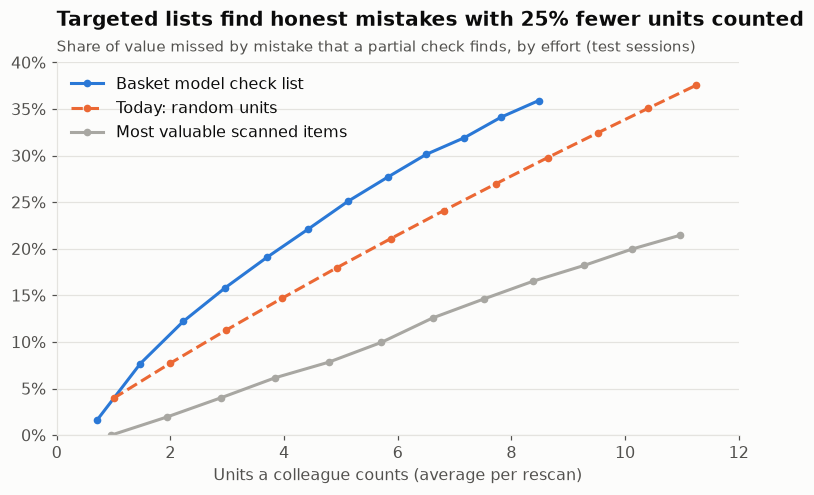

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.4))
lines = [('Basket model: value per unit counted', BLUE, 'Basket model check list', '-'),
         ('Today: random units', ORANGE, 'Today: random units', '--'),
         ('Most valuable scanned items', GREY, 'Most valuable scanned items', '-')]
for name, color, label, ls in lines:
    d = ev[ev.method == name].sort_values('budget')
    ax.plot(d.units_counted, d.accidental, color=color, marker='o', ms=4, label=label, ls=ls)
ax.yaxis.set_major_formatter(pct())
ax.set_xlabel('Units a colleague counts (average per rescan)')
ax.set_xlim(0, 12)
ax.set_ylim(0, 0.4)
m5 = ev[(ev.method == lines[0][0]) & (ev.budget == 5)].iloc[0]
r5 = ev[(ev.method == 'Today: random units') & (ev.budget == 5)].iloc[0]
ax.set_title(f'Targeted lists find honest mistakes with {1 - m5.units_counted / r5.units_counted:.0%} fewer units counted')
subtitle(ax, 'Share of value missed by mistake that a partial check finds, by effort (test sessions)')
ax.legend(loc='upper left')
save(fig, '10_basket_model_recall')
fig

**Why the gain is modest, and why that is a finding.** Genuine mistakes fall roughly at random
across the units in the bags, so picking random units already samples where they are. A model
can only add what random picks cannot see: prices, multi-buys and what was scanned. And no
partial check, however targeted, finds items concealed outside the bags. Catching deliberate
non-scanning is a question of **who gets a full rescan**: the risk model and rescan policy
(weeks 5–6).

## 4. Is "this basket looks incomplete" a risk signal?

The idea from the outline: the model's total expected missing value for a session, used to flag
risky sessions. Tested on a random sample of test sessions, with and without missing items.

In [6]:
lo, hi = TEST_DAYS
sample = con.sql(f'''
SELECT s.basket_id, t.gt_deliberate_value > 0 AS deliberate, t.gt_nonscan_units > 0 AS any_missing
FROM sim_obs.sessions s JOIN sim_truth.sessions t USING (basket_id)
WHERE s.day BETWEEN {lo} AND {hi}
''').df().sample(6000, random_state=0)
gap = score_sessions(con, model, sample.basket_id).groupby('basket_id').agg(
    gap_value=('exp_value', 'sum'), scanned_units=('n_vis_units', 'first'))
d = sample.merge(gap, left_on='basket_id', right_index=True)
d['gap_per_unit'] = d.gap_value / (d.scanned_units + 1)
pd.DataFrame({
    f: [roc_auc_score(d.deliberate, d[f]), roc_auc_score(d.any_missing, d[f])]
    for f in ['gap_value', 'gap_per_unit', 'scanned_units']
}, index=['AUC: deliberate session', 'AUC: anything missing']).round(3)

,gap_value,gap_per_unit,scanned_units
AUC: deliberate session,0.557,0.550,0.544
AUC: anything missing,0.783,0.511,0.791


The total gap mostly restates basket size (bigger baskets have more to miss); per scanned unit it
carries a little signal for deliberate sessions. It goes into the week 5 risk model as one
feature among many, not as a detector on its own.

## 5. What the model relies on

In [7]:
imp = pd.Series(model.booster_.feature_importance('gain'), index=model.booster_.feature_name())
(imp / imp.sum()).sort_values(ascending=False).head(10).round(3)

vis_units      0.560
m_rate         0.108
m_units        0.063
lift_max       0.039
days_since     0.038
popularity     0.032
n_vis_comm     0.030
lift_n_pos     0.020
lift_mean      0.017
prior_trips    0.016
dtype: float64

`vis_units` (how many of this type were scanned) carries the short-count signal, with the
member's usual units of that type (`m_units`) and how often they buy it (`m_rate`).
Co-occurrence (`lift_*`) fills in types that were never scanned.

## 6. One check list

A colleague's screen for one randomly chosen test session: what was scanned, the three types to
count, and (hidden truth) what was really missing.

In [8]:
miss = truth[truth.basket_id.isin(ids)].groupby('basket_id').miss_value.sum()
example = miss[miss.between(5, 15)].sample(1, random_state=7).index[0]
s = scored[scored.basket_id == example]
s = s.assign(priority=s.exp_value / (s.vis_units.clip(lower=1) + s.p_missing))
scanned = s[s.vis_units > 0].sort_values('vis_units', ascending=False)
print('Scanned:', ', '.join(f"{r.commodity.title()} x{int(r.vis_units)}" for r in scanned.itertuples()))
t = truth[truth.basket_id == example].set_index('commodity')
print('Really missing:', ', '.join(f"{c.title()} x{int(n)}" for c, n in t.miss_units.items()))
top = s.nlargest(3, 'priority')[['commodity', 'vis_units', 'p_missing', 'exp_value']]
top['actually_missing_units'] = top.commodity.map(t.miss_units).fillna(0).astype(int)
top.round(3)

Scanned: Vegetables - Shelf Stable x8, Organics Fruit & Vegetables x5, Beans - Canned Glass & Mw x4, Tropical Fruit x4, Refrigerated x4, Frzn Meat/Meat Dinners x4, Cheese x3, Water - Carbonated/Flvrd Drink x3, Fluid Milk Products x2, Household Cleang Needs x2, Peppers-All x2, Baked Bread/Buns/Rolls x2, Beers/Ales x2, Chicken x2, Baby Hbc x2, Misc. Dairy x2, Frzn Vegetable/Veg Dsh x1, Dried Fruit x1, Frozen x1, Cold Cereal x1, Chips&Snacks x1, Cereal/Breakfast x1, Fd Wraps/Bags/Trsh Bg x1, Paper Towels x1, Onions x1, Ice Cream/Milk/Sherbts x1, Mushrooms x1, Soap - Liquid & Bar x1, Smoked Meats x1, Processed x1, Stone Fruit x1
Really missing: Dried Fruit x1, Dry Bn/Veg/Potato/Rice x1


,commodity,vis_units,p_missing,exp_value,actually_missing_units
1844675,DIAPERS & DISPOSABLES,0.0,0.165,1.850,0
1844664,COLD CEREAL,1.0,0.212,0.574,0
1844714,GRAPES,0.0,0.180,0.546,0


## Findings

| # | Finding | Implication |
|---|---|---|
| 1 | About half of missing value is short counts of a scanned type, half types never scanned | The model scores every product type, scanned or not |
| 2 | Masked-basket model: held-out AUC 0.93 and calibrated (mean prediction 0.26% vs 0.25% actual), trained without any theft label | "What should be in this trolley", fair by design |
| 3 | At the same budget, its check list finds as many honest mistakes as today's random units while counting about 25% fewer units (1.3–1.5x found per unit counted) | Faster, friendlier partial rescans for honest shoppers |
| 4 | Simple rules do worse than random: "check the most valuable scanned items" finds about a third as much per unit | Intuition is not enough; measure against random |
| 5 | No partial check finds much deliberate loss (concealed items), and the basket gap is a weak risk signal on its own | Theft is caught by choosing *who* gets a full rescan (weeks 5–6), not by item lists |

**Limit.** The simulator spreads genuine mistakes evenly across units (apart from multi-buys and
basket size). If real mistakes cluster on particular products (bulky items, loose produce,
multi-buy promotions), targeted lists gain more; the random floor of full rescans would show it.